# OFDM 补充实验
配对 CP 多信噪比实验和 LS 等效 SNR 理论。原有实验数据保留。

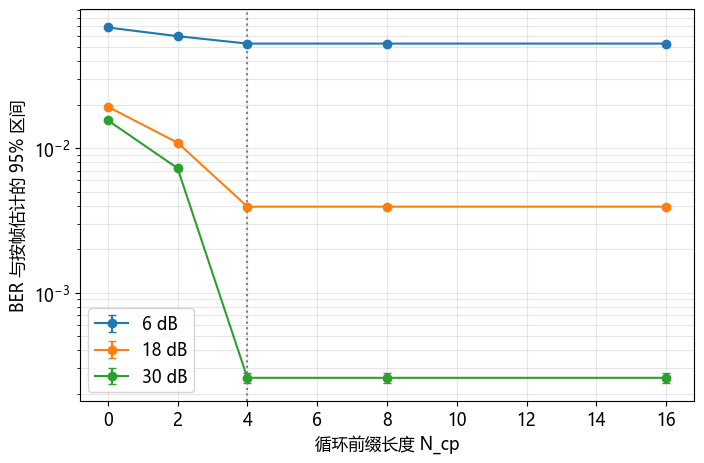

图13  三个信噪比下的配对 CP 比较（五个种子，每点 10000 个独立信道帧）
充分 CP 判决差异比特数: 0
{'EbN0_dB': 6, 'N_cp': 0, 'BER': np.float64(0.06834521484375), 'SE_frame': np.float64(0.0003825730878035906), 'CI95_low': np.float64(0.06759537159165496), 'CI95_high': np.float64(0.06909505809584504), 'independent_frames': 10000, 'counted_bits': 10240000, 'seeds': '27101|27102|27103|27104|27105'}
{'EbN0_dB': 6, 'N_cp': 2, 'BER': np.float64(0.05952998046875), 'SE_frame': np.float64(0.0003755182446691158), 'CI95_low': np.float64(0.05879396470919853), 'CI95_high': np.float64(0.06026599622830147), 'independent_frames': 10000, 'counted_bits': 10240000, 'seeds': '27101|27102|27103|27104|27105'}
{'EbN0_dB': 6, 'N_cp': 4, 'BER': np.float64(0.05289033203125), 'SE_frame': np.float64(0.00037389814453632123), 'CI95_low': np.float64(0.052157491667958814), 'CI95_high': np.float64(0.05362317239454119), 'independent_frames': 10000, 'counted_bits': 10240000, 'seeds': '27101|27102|27103|27104|27105'}
{'EbN0_dB': 6, 'N_cp': 8, 'BER': np.float64(

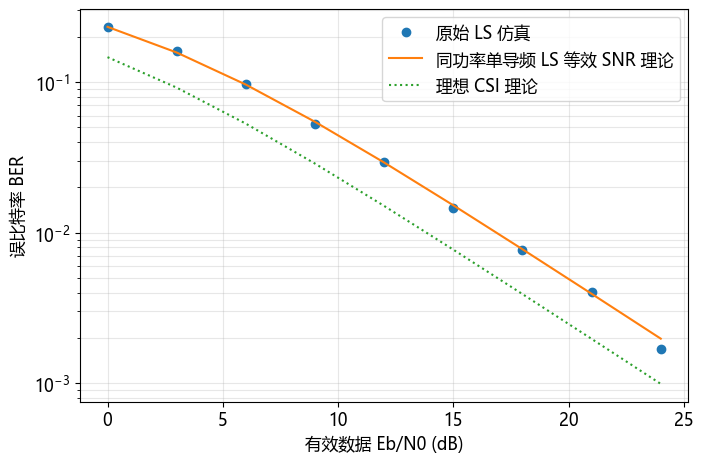

图14  保存的 LS 仿真与带噪导频等效 SNR 理论对照
{'EbN0_dB': 0.0, 'BER_ideal': 0.1463125, 'BER_LS': 0.232529296875, 'BER_ratio': 1.5892647372917557, 'BER_ratio_dB': np.float64(2.0119624734478654), 'LS_theory': np.float64(0.2327387580875756), 'SNR_loss_vs_ideal_theory_dB': np.float64(3.9698704565717033), 'SNR_loss_exact_theory_dB': np.float64(3.979400086720376)}
{'EbN0_dB': 3.0, 'BER_ideal': 0.09388671875, 'BER_LS': 0.159841796875, 'BER_ratio': 1.7024963594757645, 'BER_ratio_dB': np.float64(2.3108619191446906), 'LS_theory': np.float64(0.15724217570094481), 'SNR_loss_vs_ideal_theory_dB': np.float64(3.64689527766176), 'SNR_loss_exact_theory_dB': np.float64(3.5229708277992486)}
{'EbN0_dB': 6.0, 'BER_ideal': 0.05265234375, 'BER_LS': 0.0966015625, 'BER_ratio': 1.8347058387120707, 'BER_ratio_dB': np.float64(2.635664430486095), 'LS_theory': np.float64(0.09629147556731621), 'SNR_loss_vs_ideal_theory_dB': np.float64(3.2939506271022703), 'SNR_loss_exact_theory_dB': np.float64(3.2748038120663896)}
{'EbN0_dB': 9.0, 

In [1]:
"""CP paired multi-SNR experiment and equivalent-SNR noisy-pilot QPSK theory.

Uses the delivered OFDM functions without rerunning or clearing old notebooks.
Eb/N0 excludes CP and pilot energy. CP experiment discards one warmup symbol.
"""
import ast
import csv
import json
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt


def workspace():
    here = Path(__file__).resolve().parent.parent if '__file__' in globals() else Path.cwd().parent
    return here


def load_dut(work):
    nb = json.loads((work / 'notebooks/03A_ofdm.ipynb').read_text(encoding='utf-8'))
    names = {'qpsk_modulate', 'qpsk_demodulate', 'ofdm_modulate',
             'ofdm_demodulate', 'apply_multipath_time', 'extract_ofdm_symbols',
             'channel_frequency_response', 'zf_equalize'}
    nodes = []
    for c in nb['cells']:
        if c['cell_type'] == 'code':
            nodes += [n for n in ast.parse(''.join(c['source'])).body
                      if isinstance(n, ast.FunctionDef) and n.name in names]
    ns = dict(torch=torch, np=np, DEVICE='cpu', NUM_SUBCARRIERS=64, PATH_DELAYS=[0, 1, 4])
    exec(compile(ast.Module(body=nodes, type_ignores=[]), '<delivered OFDM>', 'exec'), ns)
    return ns


def rayleigh(g):
    return .5 / ((1 + g) * (1 + np.sqrt(g / (1 + g))))


def inverse_rayleigh(p):
    return (1 - 2*p)**2 / (4*p*(1-p))


def main():
    work = workspace()
    data = work / 'notebooks/data'; figures = work / 'notebooks/figures'
    f = load_dut(work)
    plt.rcParams.update({'font.family': 'Microsoft YaHei', 'font.size': 12})
    seeds = [27101, 27102, 27103, 27104, 27105]
    cps = [0, 2, 4, 8, 16]; snrs = [6, 18, 30]
    frames_per_seed = 2000; chunk = 250; symbols = 8
    rates = {(db, cp): [] for db in snrs for cp in cps}
    max_sufficient_disagreements = 0
    with torch.inference_mode():
        for seed in seeds:
            rng = np.random.default_rng(seed)
            for start in range(0, frames_per_seed, chunk):
                b = min(chunk, frames_per_seed-start)
                # One preceding OFDM symbol supplies channel memory; its bits are not counted.
                bits = torch.tensor(rng.integers(0, 2, (b, symbols+1, 64, 2)), dtype=torch.int32)
                x = f['qpsk_modulate'](bits)
                taps = torch.tensor((rng.standard_normal((b, 3)) + 1j*rng.standard_normal((b, 3)))/np.sqrt(6), dtype=torch.complex64)
                h = f['channel_frequency_response'](taps)
                # Unitary FFT preserves white complex Gaussian noise covariance.
                # Reuse this frequency-domain noise for all CP values and all SNRs.
                z = torch.tensor((rng.standard_normal((b, symbols, 64)) + 1j*rng.standard_normal((b, symbols, 64)))/np.sqrt(2), dtype=torch.complex64)
                clean = {}
                for cp in cps:
                    stream = f['ofdm_modulate'](x, cp).reshape(b, -1)
                    y = f['apply_multipath_time'](stream, taps)
                    clean[cp] = f['extract_ofdm_symbols'](y, symbols+1, cp)[:, 1:]
                for db in snrs:
                    no = 1/(2*10**(db/10))
                    decoded = {}
                    for cp in cps:
                        decoded[cp] = f['qpsk_demodulate'](f['zf_equalize'](clean[cp] + np.sqrt(no)*z, h[:, None]))
                        frame_rate = (decoded[cp] != bits[:, 1:]).float().mean(dim=(1, 2, 3)).numpy()
                        rates[db, cp].extend(frame_rate.tolist())
                    for cp in [8, 16]:
                        max_sufficient_disagreements += int((decoded[cp] != decoded[4]).sum())
    rows = []
    for db in snrs:
        for cp in cps:
            r = np.array(rates[db, cp]); mean = r.mean(); se = r.std(ddof=1)/np.sqrt(len(r))
            rows.append(dict(EbN0_dB=db, N_cp=cp, BER=mean, SE_frame=se,
                             CI95_low=max(0, mean-1.96*se), CI95_high=min(1, mean+1.96*se),
                             independent_frames=len(r), counted_bits=len(r)*symbols*64*2,
                             seeds='|'.join(map(str, seeds))))
    with (data/'04_cp_multisnr.csv').open('w', encoding='utf-8-sig', newline='') as out:
        writer = csv.DictWriter(out, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    for db in snrs:
        rr = [r for r in rows if r['EbN0_dB']==db]
        ax.errorbar(cps, [r['BER'] for r in rr], yerr=[1.96*r['SE_frame'] for r in rr], marker='o', capsize=3, label=f'{db} dB')
    ax.set_yscale('log'); ax.set_xlabel('循环前缀长度 N_cp'); ax.set_ylabel('BER 与按帧估计的 95% 区间')
    ax.axvline(4, color='gray', ls=':'); ax.grid(True, which='both', alpha=.3); ax.legend()
    fig.tight_layout(); fig.savefig(figures/'04_cp_multisnr.png', dpi=200); plt.show()
    print('图13  三个信噪比下的配对 CP 比较（五个种子，每点 10000 个独立信道帧）')
    print('充分 CP 判决差异比特数:', max_sufficient_disagreements)
    for row in rows: print(row)
    lsrows = []
    with (data/'03A_ls_estimation.csv').open(encoding='utf-8-sig') as src:
        for r in csv.DictReader(src):
            db = float(r['EbN0_dB']); g = 10**(db/10); no = 1/(2*g)
            ideal = float(r['BER_理想CSI']); ls = float(r['BER_LS估计'])
            lsrows.append(dict(EbN0_dB=db, BER_ideal=ideal, BER_LS=ls,
                BER_ratio=ls/ideal, BER_ratio_dB=10*np.log10(ls/ideal),
                LS_theory=rayleigh(g/(2+no)),
                SNR_loss_vs_ideal_theory_dB=db-10*np.log10(inverse_rayleigh(ls)),
                SNR_loss_exact_theory_dB=10*np.log10(2+no)))
    with (data/'04_ls_snr_loss.csv').open('w', encoding='utf-8-sig', newline='') as out:
        writer = csv.DictWriter(out, fieldnames=list(lsrows[0])); writer.writeheader(); writer.writerows(lsrows)
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    db = np.array([r['EbN0_dB'] for r in lsrows]); g=10**(db/10)
    ax.semilogy(db, [r['BER_LS'] for r in lsrows], 'o', label='原始 LS 仿真')
    ax.semilogy(db, rayleigh(g/(2+1/(2*g))), '-', label='同功率单导频 LS 等效 SNR 理论')
    ax.semilogy(db, rayleigh(g), ':', label='理想 CSI 理论')
    ax.set_xlabel('有效数据 Eb/N0 (dB)'); ax.set_ylabel('误比特率 BER'); ax.grid(True, which='both', alpha=.3); ax.legend()
    fig.tight_layout(); fig.savefig(figures/'04_ls_exact_theory.png', dpi=200); plt.show()
    print('图14  保存的 LS 仿真与带噪导频等效 SNR 理论对照')
    for row in lsrows: print(row)
    print('配置：CP 与导频能量不计入横轴；各 CP 共用比特、信道和频域噪声；丢弃一符号预热；区间按独立信道帧估计。')
    return rows, lsrows


if __name__ == '__main__':
    main()
